# Estimación de costos médicos para planificación agregada
Grupo 2 · Gestión de Proyectos de Datos SCY1102 · Duoc UC

Daniel Cabrera Araya, Martín Carrasco Lineros, Fabián Solar y David Vásquez Ovalle.

Este cuaderno reproduce el paquete final de implementación. Ejecútalo desde la carpeta `04_Implementacion`, con las dependencias de `requirements.txt`. La comparación completa se realiza en la sección 2 y puede tardar alrededor de un minuto en el equipo de validación. La ejecución regenera evidencias locales.

El dataset no acredita moneda, país o período. `charges` se expresa en **unidades monetarias (u.m.)**. El presupuesto del proyecto se expresa separadamente en CLP. La predicción no autoriza decisiones sobre primas, afiliación, cobertura o acceso a atención.


In [1]:
from pathlib import Path
import sys, os, json, subprocess
import numpy as np
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from IPython.display import Image
BASE = Path.cwd()
assert (BASE / 'medical_cost.py').exists(), 'Abra el notebook desde la carpeta 04_Implementacion.'
sys.path.insert(0, str(BASE))
from medical_cost import cargar_datos, validar_datos, alerta_gasto, FEATURES, SEED
print('Entorno y rutas preparados. Semilla:', SEED)


Entorno y rutas preparados. Semilla: 42


## 1 Datos y calidad RD1
Se verifica el esquema antes de eliminar el duplicado exacto. La eliminación es una decisión de limpieza académica; sin identificador no puede determinarse si eran dos personas distintas.

In [2]:
raw, df = cargar_datos('insurance.csv')
print('Originales:', len(raw), 'Únicos:', len(df), 'Nulos:', int(raw.isna().sum().sum()))
df.describe().round(2)


Originales: 1338 Únicos: 1337 Nulos: 0


,age,bmi,children,charges
count,1337.00,1337.00,1337.00,1337.00
mean,39.22,30.66,1.10,13279.12
std,14.04,6.10,1.21,12110.36
min,18.00,15.96,0.00,1121.87
25%,27.00,26.29,0.00,4746.34
50%,39.00,30.40,1.00,9386.16
75%,51.00,34.70,2.00,16657.72
max,64.00,53.13,5.00,63770.43


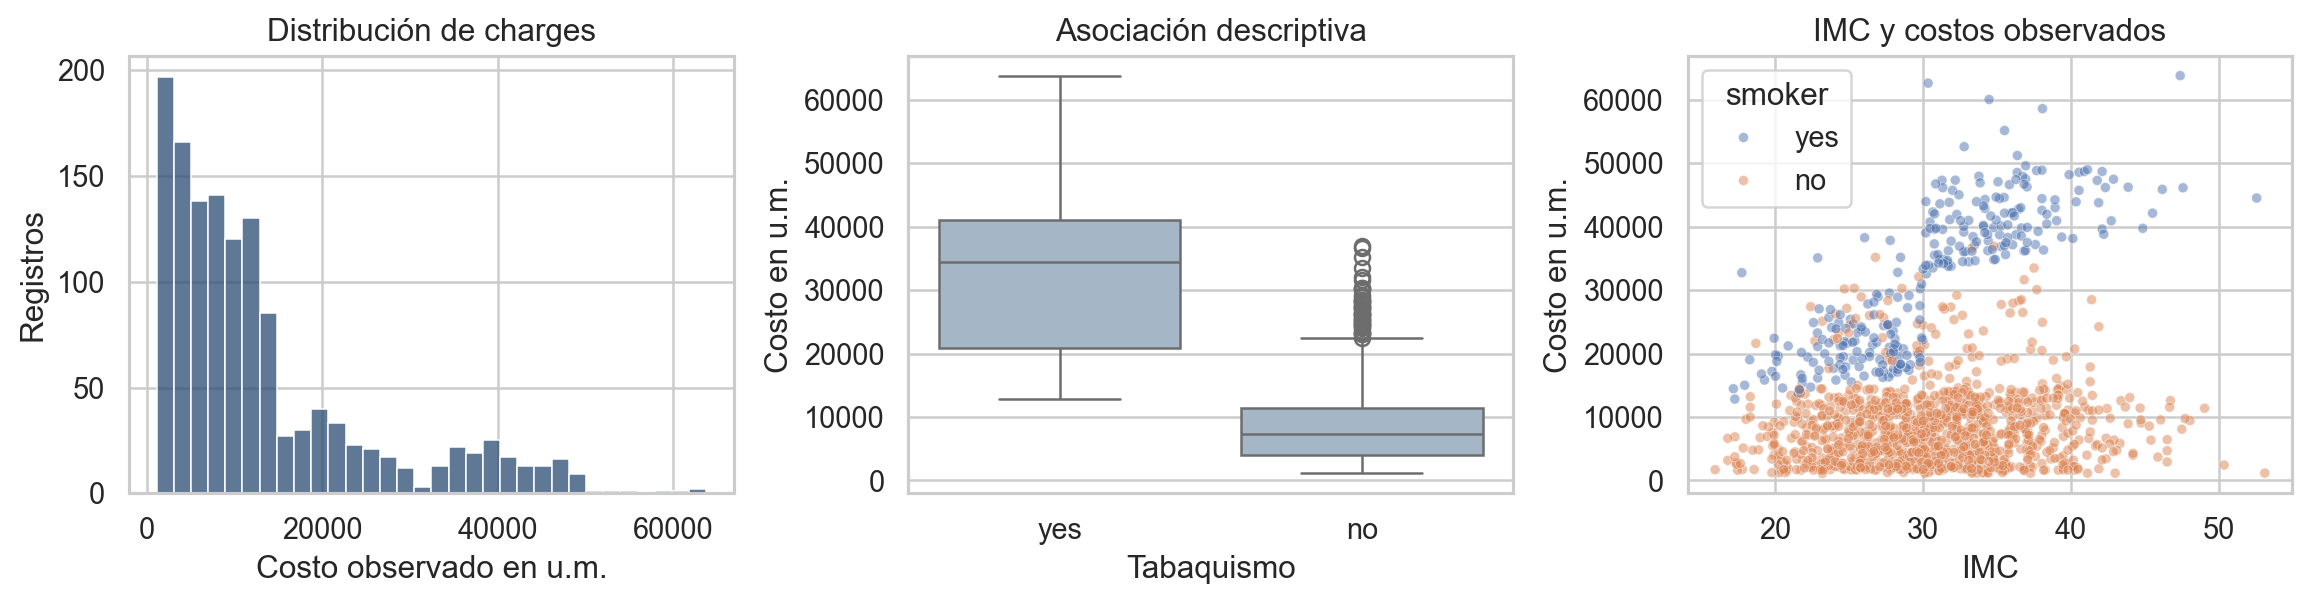

In [3]:
Image(filename='evidencias/figuras/eda.png')

## 2 Entrenamiento y validación RF1
Se comparan regresión lineal, RF base, RF manual y Gradient Boosting. La grilla prueba 32 combinaciones de Random Forest con cinco particiones. `medical_cost.py` conserva el esquema, la selección, los controles de entradas, la auditoría y las pruebas funcionales. El preprocesamiento forma parte del pipeline.

La selección usa R² de CV en entrenamiento. El conjunto de prueba ya fue observado en el avance: sus resultados son internos. La CV del ganador también fue usada para seleccionarlo y puede ser optimista. Una nueva decisión requiere protocolo congelado y validación anidada o una muestra externa reservada.


In [4]:
env = os.environ.copy()
env['PYTHONIOENCODING'] = 'utf-8'
run = subprocess.run([sys.executable, '-u', 'ejecutar_validacion.py'], cwd=BASE,
                     env=env, text=True, encoding='utf-8', errors='replace', capture_output=True)
print(run.stdout)
if run.returncode:
    print(run.stderr)
run.check_returncode()


Cargando y validando datos
Comparando modelos y realizando validación cruzada
Exportando métricas y ejecutando pruebas funcionales
{
  "r2_prueba": 0.9028280006344899,
  "mae_prueba": 2458.438137922895,
  "rmse_prueba": 4225.629436949051,
  "r2_cv": 0.8444225229098958,
  "sd_r2_cv": 0.02741372327655689,
  "r2_train": 0.8630963460335568,
  "error_cartera_pct": 0.628233211091489,
  "sesgo_decil_superior_pct": -4.4494051485020165,
  "n_decil_superior": 27,
  "cobertura_nominal": 0.8,
  "residuo_q10": -2585.0733230546302,
  "residuo_q90": 2670.1120059003774,
  "cobertura_observada": 0.7798507462686567,
  "cubiertos": 209,
  "n_prueba": 268,
  "n_entrenamiento": 1069,
  "unidad_charges": "u.m. sin moneda acreditada",
  "semilla": 42,
  "parametros_seleccionados": {
    "modelo__max_depth": 4,
    "modelo__min_samples_leaf": 10,
    "modelo__n_estimators": 200
  },
  "latencia_lote_prueba_268_filas_ms_mediana_10": 20.09555001859553,
  "version": "2.0-academica",
  "registros_originales": 133

In [5]:
comparacion = pd.read_csv('evidencias/comparacion_modelos.csv')
comparacion.round(4)

,modelo,r2_cv,sd_r2_cv,mae_cv,r2_train,r2_test,mae_test
0,Regresión lineal,0.7228,0.0283,4221.9633,0.7299,0.8069,4177.0456
1,RF base,0.8159,0.0312,2794.7975,0.9737,0.8797,2637.9945
2,RF manual,0.8394,0.0249,2578.6169,0.8959,0.8988,2434.1902
3,Gradient Boosting,0.8390,0.0263,2601.3402,0.8815,0.9013,2507.0354
4,RF grilla seleccionado,0.8444,0.0274,2587.8933,0.8631,0.9028,2458.4381


## 3 Evaluación y recarga del pipeline
Se recalculan las métricas después de cargar el archivo serializado y se comprueba que coinciden con las evidencias exportadas.

In [6]:
metricas = json.loads(Path('evidencias/metricas.json').read_text(encoding='utf-8'))
modelo = joblib.load('evidencias/pipeline_medical_cost.joblib')
X_train, X_test, y_train, y_test = train_test_split(df[FEATURES], df.charges, test_size=.2, random_state=SEED)
pred = modelo.predict(X_test)
assert np.isclose(r2_score(y_test, pred), metricas['r2_prueba'])
assert np.isclose(mean_absolute_error(y_test, pred), metricas['mae_prueba'])
assert np.isclose(mean_squared_error(y_test, pred)**.5, metricas['rmse_prueba'])
inferior = np.maximum(0, pred + metricas['residuo_q10'])
superior = pred + metricas['residuo_q90']
cobertura = np.mean((y_test >= inferior) & (y_test <= superior))
assert np.isclose(cobertura, metricas['cobertura_observada'])
print(f"R² {metricas['r2_prueba']:.4f}; MAE {metricas['mae_prueba']:.2f}; RMSE {metricas['rmse_prueba']:.2f} u.m.")
print(f'Cobertura nominal 80 %; observada {100*cobertura:.1f} % en 268 filas.')


R² 0.9028; MAE 2458.44; RMSE 4225.63 u.m.
Cobertura nominal 80 %; observada 78.0 % en 268 filas.


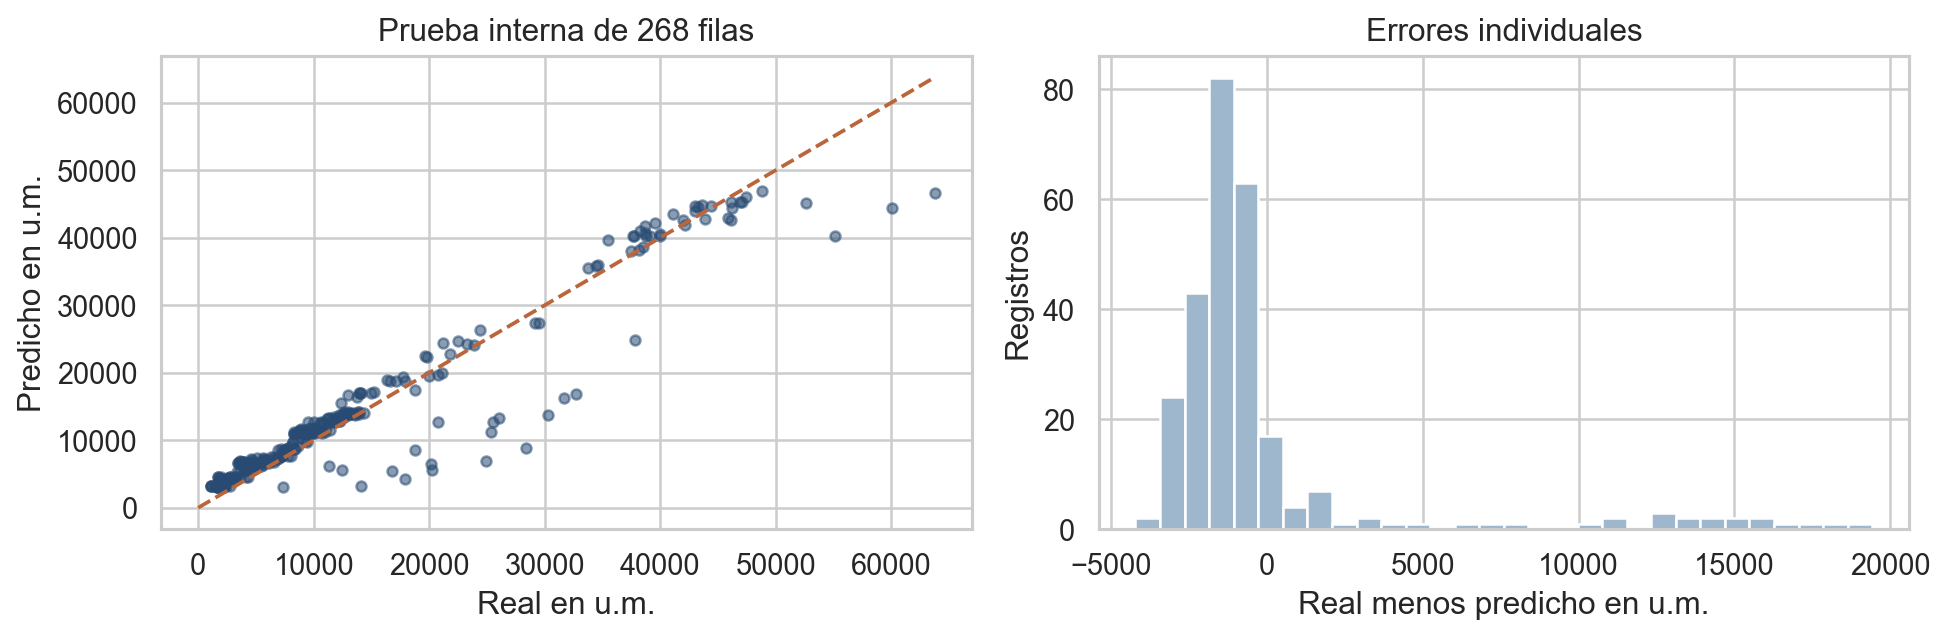

In [7]:
Image(filename='evidencias/figuras/diagnostico.png')

## 4 Factores predictivos RF3
La importancia por reducción de impureza describe el modelo ajustado. No mide causalidad y puede favorecer algunas variables. El panel interactivo del avance permanece diferido.

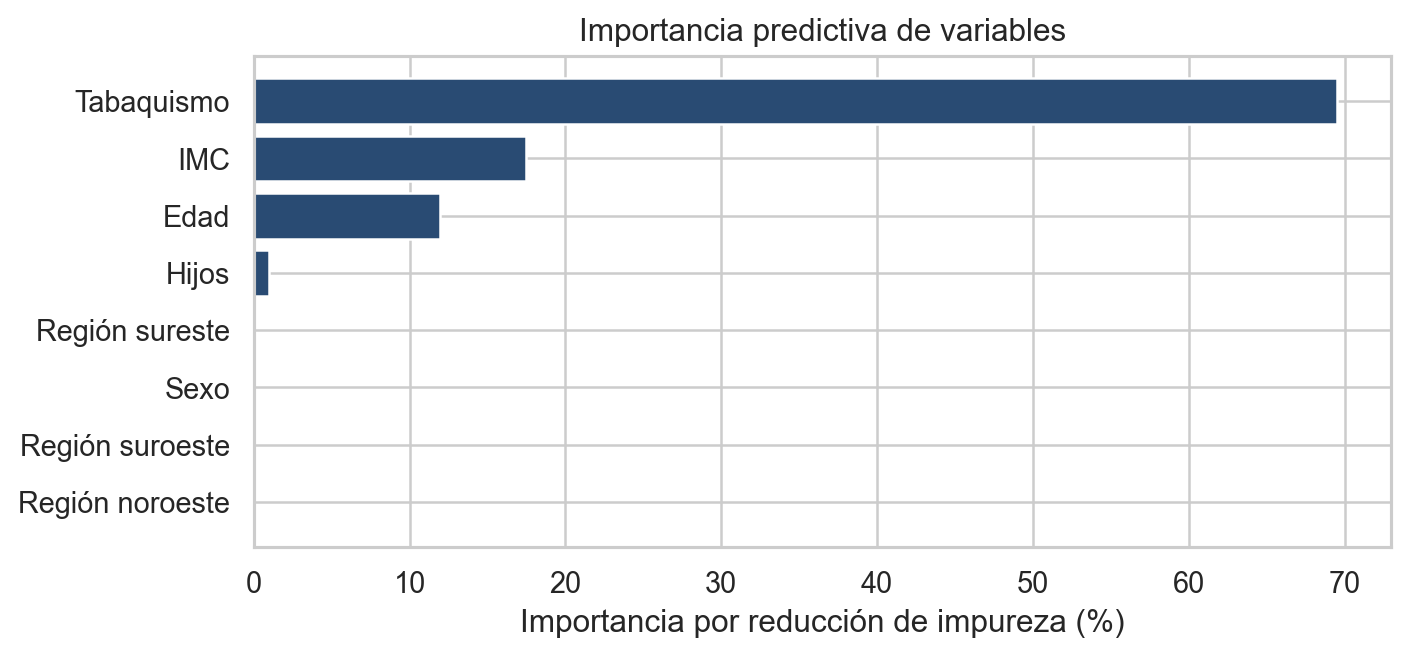

In [8]:
Image(filename='evidencias/figuras/importancia.png')

## 5 Equidad RF4
Se mantiene el criterio original: `(MAE máximo - mínimo) / mínimo ≤ 15 %` por variable. Los intervalos bootstrap del 95 % usan 1.000 remuestreos dentro de cada subgrupo y describen incertidumbre del MAE. La igualdad de una métrica no acredita equidad por sí sola. La acción correctiva no cambia retrospectivamente el límite.


In [9]:
auditoria = pd.read_csv('evidencias/auditoria_subgrupos.csv')
brechas = pd.read_csv('evidencias/brechas_equidad.csv')
print(brechas.round(2).to_string(index=False))
auditoria.round(2)

  variable  brecha_mae_pct  limite_pct  cumple
       sex           11.68          15    True
    region           34.28          15   False
    smoker           22.84          15   False
 rango_imc           49.90          15   False
rango_edad            6.99          15    True


,variable,subgrupo,n,mae,costo_medio,error_relativo_pct,ic95_mae_inferior,ic95_mae_superior
0,sex,female,143,2331.47,13528.13,17.23,1801.31,2987.80
1,sex,male,125,2603.68,15123.00,17.22,2090.93,3213.78
2,region,northeast,71,2919.41,13995.18,20.86,2019.24,3980.37
3,region,northwest,60,2345.80,14842.25,15.80,1490.13,3419.80
4,region,southeast,77,2342.76,15409.11,15.20,1809.74,3039.86
5,region,southwest,60,2174.05,12570.06,17.30,1650.48,2888.37
6,smoker,no,208,2338.85,8202.99,28.51,1896.33,2802.60
7,smoker,yes,60,2873.02,35311.26,8.14,1977.52,3904.23
8,rango_imc,hasta 25,46,1963.47,9935.93,19.76,1470.88,2753.78
9,rango_imc,mayor 25 hasta 30,69,2943.24,11421.26,25.77,2064.49,3930.29


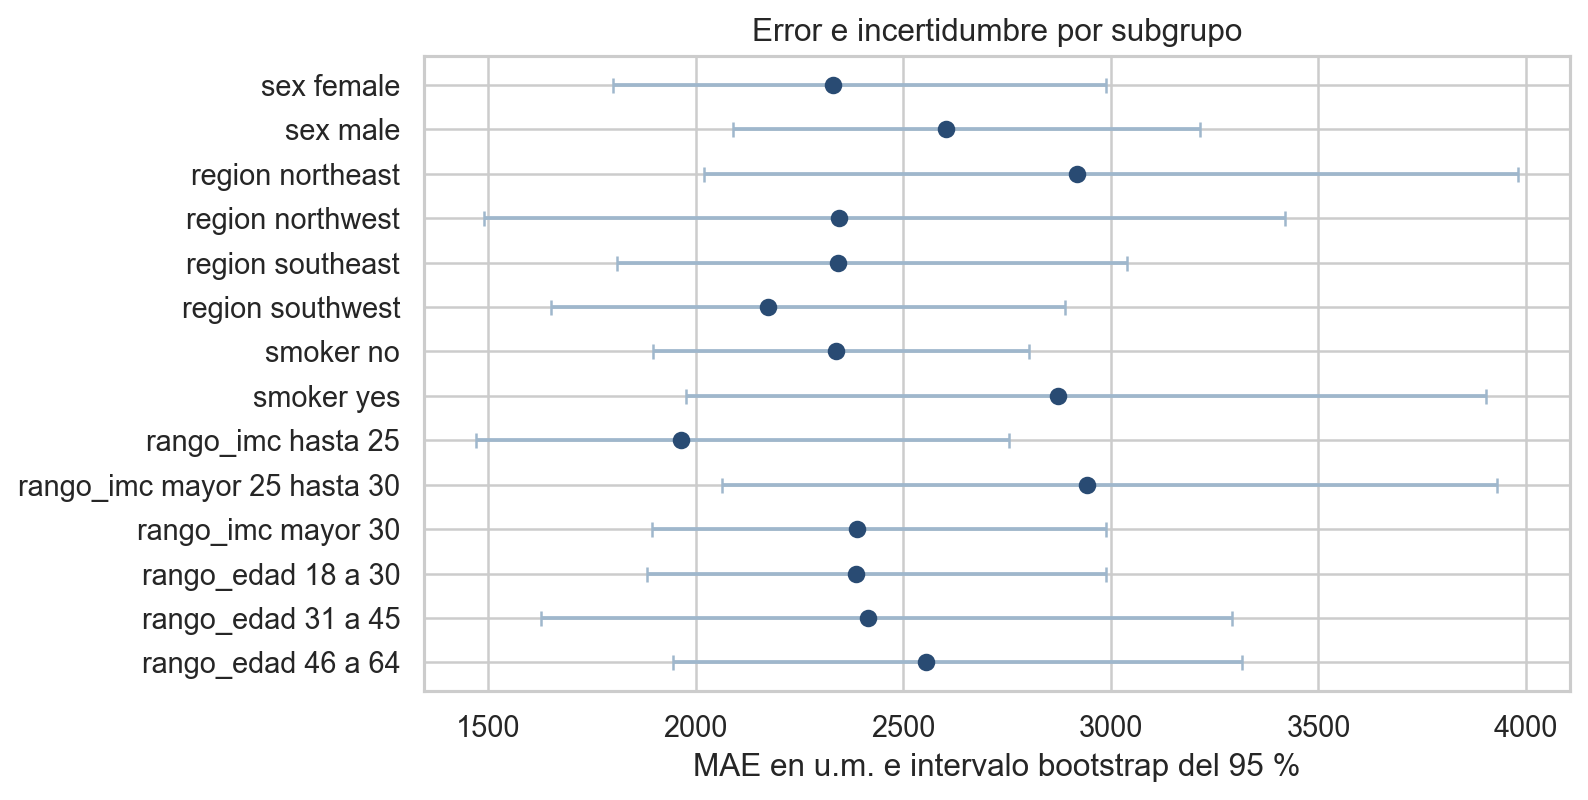

In [10]:
Image(filename='evidencias/figuras/equidad_intervalos.png')

## 6 Costos extremos y presupuesto R5
El error total de cartera en una partición puede ocultar compensación entre sobreestimaciones y subestimaciones. El decil superior se define con los costos reales de la prueba e incluye 27 filas. Estos resultados no demuestran ahorro ni desempeño fuera de la muestra.


In [11]:
print(f"Error de cartera: {metricas['error_cartera_pct']:+.2f} %")
print(f"Sesgo del decil superior: {metricas['sesgo_decil_superior_pct']:+.2f} %")


Error de cartera: +0.63 %
Sesgo del decil superior: -4.45 %


## 7 Ejemplos didácticos y límite RNF4
Las siguientes cinco filas son perfiles hipotéticos individuales. No constituyen promedios de cohortes. Los rangos empíricos tienen ancho constante y no garantizan cobertura por subgrupo. El mínimo de veinte filas se aplica a la alerta operativa, no a todo acceso al artefacto. RNF4 continúa parcial.


In [12]:
pd.read_csv('evidencias/predicciones_didacticas.csv').round(0)

,perfil,age,sex,bmi,children,smoker,region,prediccion_um,rango80_inferior,rango80_superior
0,Adulto joven,25,female,22.0,0,no,southwest,4341.0,1755.0,7011.0
1,Adulto con IMC alto,40,male,34.0,2,no,southeast,7538.0,4952.0,10208.0
2,Fumador de mediana edad,45,male,28.0,1,yes,northwest,25667.0,23082.0,28338.0
3,Fumador con IMC alto,35,female,35.0,0,yes,northeast,40053.0,37468.0,42723.0
4,Adulto mayor no fumador,60,female,27.0,0,no,northeast,13829.0,11244.0,16499.0


## 8 Automatización y pruebas RF2 RF5 R9
La alerta valida el lote y el umbral. La deriva usa exclusivamente la referencia de entrenamiento, pruebas KS para edad e IMC y chi-cuadrado para variables discretas, con ajuste Holm de seis comparaciones y alfa 0,01. Los lotes de demostración se construyen a partir de la misma muestra y no son una validación prospectiva.

El reentrenamiento genera un pipeline candidato y un registro, sin promoción automática. La prueba utiliza una meta de 1,0 para comprobar el caso que no cumple. Esa meta es una condición de prueba, no el requisito RF1, que se mantiene en 0,80.


In [13]:
alertas = json.loads(Path('evidencias/alertas_simuladas.json').read_text(encoding='utf-8'))
print(json.dumps(alertas, ensure_ascii=False, indent=2))
pruebas = pd.read_csv('evidencias/pruebas_funcionales.csv')
assert (pruebas.resultado == 'OK').all()
print('Pruebas satisfactorias:', len(pruebas))
pruebas


{
  "grupo_habitual": {
    "n_afiliados": 100,
    "costo_proyectado_um": 1238726.143861058,
    "umbral_um": 1300000.0,
    "alerta": false,
    "uso_porcentual_umbral": 95.2866264508506
  },
  "grupo_simulado": {
    "n_afiliados": 100,
    "costo_proyectado_um": 2286147.8574776268,
    "umbral_um": 1300000.0,
    "alerta": true,
    "uso_porcentual_umbral": 175.85752749827898
  }
}
Pruebas satisfactorias: 18


,prueba,resultado,detalle
0,Alerta negativa en grupo habitual,OK,Criterio comprobado
1,Alerta positiva en grupo simulado,OK,Criterio comprobado
2,Rechazo de grupo de 19 filas,OK,Criterio comprobado
3,Rechazo de umbral cero,OK,Criterio comprobado
4,Rechazo de umbral negativo,OK,Criterio comprobado
5,Rechazo de edad negativa,OK,Criterio comprobado
6,Rechazo de IMC fuera de rango,OK,Criterio comprobado
7,Rechazo de hijos fraccionarios,OK,Criterio comprobado
8,Rechazo de categoria desconocida,OK,Criterio comprobado
9,Rechazo de columna faltante,OK,Criterio comprobado


In [14]:
pd.read_csv('evidencias/deriva_simulada.csv').round(6)

,variable,prueba,p_sin_ajuste,esperado_minimo,p_ajuste_holm,alfa,deriva
0,age,KS,0.000000,NaN,0.0,0.01,True
1,bmi,KS,0.416166,NaN,1.0,0.01,False
2,children,Chi cuadrado,0.272081,4.382761,1.0,0.01,False
3,sex,Chi cuadrado,0.704980,146.603360,1.0,0.01,False
4,smoker,Chi cuadrado,0.000000,76.479182,0.0,0.01,True
5,region,Chi cuadrado,0.307160,71.877283,1.0,0.01,False


## 9 Conclusión y trazabilidad
La meta técnica RF1 se cumple en evaluación interna. RF4 continúa incumplido en región, tabaquismo e IMC. El paquete incorpora validación, persistencia, pruebas y un seguimiento local; la aceptación del cliente, la seguridad operativa y la validación externa permanecen abiertas. La carpeta de gestión diferencia tareas comprobadas, propuestas y la semana simulada de control.

Referencias: Choi, M. (s. f.), Medical Cost Personal Datasets, Kaggle; scikit-learn, documentación de pipelines y validación cruzada. Fuentes completas y criterios académicos en los dos informes. Para reconstruir todo sin Jupyter: `python ejecutar_validacion.py`.
